# Demand Planner: прогноз продаж

Задача — по прошлым продажам оценить, сколько единиц каждого товара продадут на следующей неделе. Позже этот прогноз понадобится для расчёта закупок.

Для начала взяты 100 товаров FOODS из магазина CA_1. История — с 29 января 2011 года по 24 апреля 2016 года. Здесь собраны загрузка данных, исследование, простые прогнозы и первые модели CatBoost. Результаты теста находятся в разделе 7.

Ячейки нужно запускать сверху вниз в окружении `.venv` проекта. В списке ядер оно может называться Python (demand-planner).

## 0. Окружение и пути

Подключаем библиотеки и находим папку проекта.

pandas нужен для таблиц, NumPy — для вычислений, Matplotlib — для графиков, CatBoost — для моделей. `Path` и `sys` используем для путей и проверки окружения Python.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from catboost import CatBoostRegressor

Корень проекта ищем по файлу `requirements.txt` и папке `src`. Затем проверяем, что выбран Python из проектной `.venv`, и настраиваем импорт `src.data`.

Пути к исходным данным, готовой таблице и результатам сохраняем в переменные. `RANDOM_STATE = 42` позволяет повторить выбор товаров и обучение. Прогнозируем сумму за семь дней, то есть одну полную неделю.

In [2]:
current_dir = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in [current_dir, *current_dir.parents]
     if (path / 'requirements.txt').is_file() and (path / 'src').is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError('Откройте ноутбук из папки demand-planner или notebooks.')
if Path(sys.prefix).resolve() != (PROJECT_ROOT / '.venv').resolve():
    raise RuntimeError('Выберите ядро Python (demand-planner) из окружения .venv.')

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_RAW = PROJECT_ROOT / 'data' / 'raw'
DATA_PROCESSED = PROJECT_ROOT / 'data' / 'processed'
RESULTS = PROJECT_ROOT / 'results'
RANDOM_STATE = 42
FORECAST_HORIZON = 7

pd.set_option('display.max_columns', 30)
print(f'Python: {sys.version.split()[0]}')
print(f'Проект: {PROJECT_ROOT}')
print(f'Данные: {DATA_RAW}')
print(f'Горизонт прогноза: {FORECAST_HORIZON} дней')

Python: 3.12.14
Проект: /Users/daniilsestov/Desktop/pet_projects/demand-planner
Данные: /Users/daniilsestov/Desktop/pet_projects/demand-planner/data/raw
Горизонт прогноза: 7 дней


## 1. Загрузка данных

Данные — из [M5 Forecasting — Accuracy](https://www.kaggle.com/competitions/m5-forecasting-accuracy/data). Архив скачиваем с [Zenodo](https://zenodo.org/records/12636070).

Понадобятся три файла:

- `sales_train_validation.csv` — продажи каждого товара в магазине по дням;
- `calendar.csv` — даты и календарные события;
- `sell_prices.csv` — недельные продажные цены.

Начинаем со случайных 100 товаров FOODS в CA_1. Для выбора используем seed 42, поэтому при повторном запуске набор будет тем же.

Задаём магазин, категорию и число товаров. `download_m5` скачивает отсутствующий архив и проверяет контрольные суммы архива и CSV. Если файлы уже есть, использует их. В выводе — размеры файлов и их MD5.

In [3]:
from src.data import download_m5, load_subset, build_panel

STORE_ID = 'CA_1'
CATEGORY = 'FOODS'
N_ITEMS = 100

raw_files = download_m5(DATA_RAW)
display(raw_files)

,file,bytes,md5
0,calendar.csv,103469,3ffeab2991b0c8e861d008b39ea4c95c
1,sales_train_validation.csv,120007726,26a366a25beb57b0a8f4c7b148758f94
2,sell_prices.csv,203395785,08c591caa99e55daf3e0ccac913f7c85


Большие CSV читаются частями. В памяти остаются продажи и цены только выбранных товаров; календарь загружается целиком.

Первая таблица показывает размеры исходных данных, вторая — нашей выборки. В полном файле 30 490 рядов «товар–магазин», в дальнейших расчётах пока участвуют 100.

In [4]:
calendar, sales, prices, source_shapes = load_subset(
    DATA_RAW, store_id=STORE_ID, category=CATEGORY,
    n_items=N_ITEMS, seed=RANDOM_STATE,
)
display(source_shapes)

subset_shapes = pd.DataFrame([
    {'table': 'calendar', 'rows': len(calendar), 'columns': calendar.shape[1]},
    {'table': 'sales: выбранные товары', 'rows': len(sales), 'columns': sales.shape[1]},
    {'table': 'prices: выбранные товары', 'rows': len(prices), 'columns': prices.shape[1]},
])
display(subset_shapes)

,table,rows,columns
0,calendar,1969,14
1,sales_train_validation,30490,1919
2,sell_prices,6841121,4


,table,rows,columns
0,calendar,1969,14
1,sales: выбранные товары,100,1919
2,prices: выбранные товары,23517,4


Смотрим, как устроены исходные таблицы. В продажах каждый день пока записан отдельным столбцом: `d_1`, `d_2` и так далее. По `d` можно присоединить дату из календаря, а по товару, магазину и номеру недели — цену.

In [5]:
display(sales.iloc[:3, :12])
display(calendar.head(3))
display(prices.head(3))

,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,d_5,d_6
0,FOODS_1_063_CA_1_validation,FOODS_1_063,FOODS_1,FOODS,CA_1,CA,0,1,0,0,0,1
1,FOODS_1_089_CA_1_validation,FOODS_1_089,FOODS_1,FOODS,CA_1,CA,0,0,0,0,0,0
2,FOODS_1_095_CA_1_validation,FOODS_1_095,FOODS_1,FOODS,CA_1,CA,1,1,2,0,1,1


,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0


,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,FOODS_1_063,11101,1.97
1,CA_1,FOODS_1_063,11102,1.97
2,CA_1,FOODS_1_063,11103,1.97


## 2. Проверка и подготовка таблицы

Соберём таблицу, где одна строка — товар в магазине за один день.

Нулевые продажи сохраняем. Из этих данных нельзя узнать, не было ли покупателей или самого товара на полке. Запись о цене тоже не подтверждает наличие товара.

`build_panel` переводит дневные столбцы продаж в строки и присоединяет календарь и цены. Цена задана на неделю, поэтому повторяется в нескольких дневных строках.

Функция проверяет ключи соединений, дубликаты, даты и значения продаж. Проверки ниже дополнительно убеждаются, что в `panel` попали нужные магазин, категория и число товаров.

In [6]:
panel = build_panel(calendar, sales, prices)

assert panel['item_id'].nunique() == N_ITEMS
assert panel['store_id'].nunique() == 1
assert panel['store_id'].eq(STORE_ID).all()
assert panel['cat_id'].eq(CATEGORY).all()

preview_columns = [
    'date', 'item_id', 'store_id', 'sales', 'sell_price',
    'price_available', 'weekday', 'event_name_1',
]
display(panel[preview_columns].head(10))

,date,item_id,store_id,sales,sell_price,price_available,weekday,event_name_1
0,2011-01-29,FOODS_1_063,CA_1,0,1.97,True,Saturday,NaN
1,2011-01-30,FOODS_1_063,CA_1,1,1.97,True,Sunday,NaN
2,2011-01-31,FOODS_1_063,CA_1,0,1.97,True,Monday,NaN
3,2011-02-01,FOODS_1_063,CA_1,0,1.97,True,Tuesday,NaN
4,2011-02-02,FOODS_1_063,CA_1,0,1.97,True,Wednesday,NaN
5,2011-02-03,FOODS_1_063,CA_1,1,1.97,True,Thursday,NaN
6,2011-02-04,FOODS_1_063,CA_1,1,1.97,True,Friday,NaN
7,2011-02-05,FOODS_1_063,CA_1,0,1.97,True,Saturday,NaN
8,2011-02-06,FOODS_1_063,CA_1,0,1.97,True,Sunday,SuperBowl
9,2011-02-07,FOODS_1_063,CA_1,0,1.97,True,Monday,NaN


Проверяем размер таблицы, даты, дубликаты и пропуски. Отдельно считаем нулевые продажи и строки, где продажи есть, а цены нет.

Получилось 191 300 строк: 100 товаров × 1 913 дней. Дубликатов и пропусков продаж нет. Неизвестные цены оставляем пропусками; пустое календарное событие обычно означает день без отмеченного события.

In [7]:
data_summary = pd.Series({
    'rows': len(panel),
    'items': panel['item_id'].nunique(),
    'stores': panel['store_id'].nunique(),
    'days': panel['date'].nunique(),
    'date_from': panel['date'].min().date().isoformat(),
    'date_to': panel['date'].max().date().isoformat(),
    'duplicate_item_store_date': int(panel.duplicated(['item_id', 'store_id', 'date']).sum()),
    'missing_sales': int(panel['sales'].isna().sum()),
    'zero_sales_pct': round(100 * panel['sales'].eq(0).mean(), 2),
    'missing_price_rows': int(panel['sell_price'].isna().sum()),
    'positive_sales_without_price': int((panel['sales'].gt(0) & panel['sell_price'].isna()).sum()),
}, name='value')
display(data_summary.to_frame())

column_summary = pd.DataFrame({
    'dtype': panel.dtypes.astype(str),
    'missing': panel.isna().sum(),
})
display(column_summary)

,value
rows,191300
items,100
stores,1
days,1913
date_from,2011-01-29
date_to,2016-04-24
duplicate_item_store_date,0
missing_sales,0
zero_sales_pct,55.64
missing_price_rows,32781


,dtype,missing
id,string,0
item_id,string,0
dept_id,string,0
cat_id,string,0
store_id,string,0
state_id,string,0
d,str,0
sales,int32,0
date,datetime64[us],0
wm_yr_wk,int64,0


Сохраняем готовую таблицу в Parquet, а список выбранных товаров — в CSV. Оба файла лежат в `data/processed` и исключены из Git. Parquet пригодится для быстрого повторного чтения с сохранением типов столбцов.

In [8]:
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
processed_path = DATA_PROCESSED / 'm5_ca1_foods_100.parquet'
selected_items_path = DATA_PROCESSED / 'selected_items.csv'

panel.to_parquet(processed_path, index=False)
sales[['item_id', 'dept_id', 'cat_id', 'store_id']].sort_values('item_id').to_csv(
    selected_items_path, index=False,
)
print(f'Таблица сохранена: {processed_path.name}')
print(f'Выбранные товары: {selected_items_path.name}')

Таблица сохранена: m5_ca1_foods_100.parquet
Выбранные товары: selected_items.csv


Дальше работаем с `panel`. Сначала посмотрим на продажи, затем соберём недельную таблицу для прогноза.

## 3. Исследование продаж

Посмотрим, сколько в данных нулей, как меняется число товаров с ценой и отличаются ли продажи по дням недели. Графики в этом разделе построены по всей доступной истории.

Считаем долю нулей во всей таблице и отдельно среди строк с ценой. Получается 55,64% и 46,46%.

В строках с ценой нулей меньше, но их всё равно почти половина. Поэтому обработка редких продаж будет важна и после учёта периодов без цены.

In [9]:
has_price = panel["price_available"]

zero_share_all = panel["sales"].eq(0).mean()
zero_share_with_price = panel.loc[has_price, "sales"].eq(0).mean()

print(f"Всего наблюдений: {len(panel):,}")
print(f"Наблюдений с ценой: {has_price.sum():,}")
print(f"Доля нулевых продаж во всей таблице: {zero_share_all:.2%}")
print(f"Доля нулевых продаж среди строк с ценой: {zero_share_with_price:.2%}")

Всего наблюдений: 191,300
Наблюдений с ценой: 158,519
Доля нулевых продаж во всей таблице: 55.64%
Доля нулевых продаж среди строк с ценой: 46.46%


На верхнем графике — сумма дневных продаж всех 100 товаров. Линия среднего за семь дней сглаживает колебания и помогает увидеть общий уровень.

Нижний график показывает число товаров с ценой. Оно выросло с 49 до 100. При анализе общей суммы продаж нужно учитывать и это изменение состава.

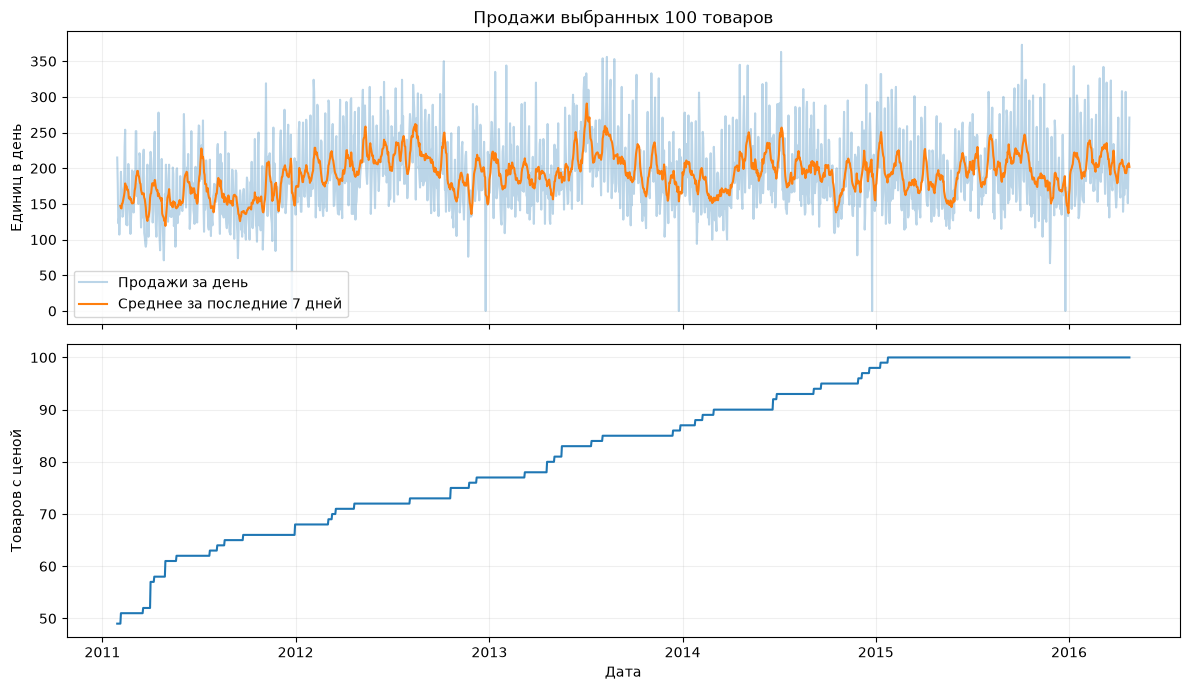

In [10]:
daily = panel.groupby("date").agg(
    total_sales=("sales", "sum"),
    products_with_price=("price_available", "sum"),
)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

axes[0].plot(
    daily.index,
    daily["total_sales"],
    alpha=0.3,
    label="Продажи за день",
)
axes[0].plot(
    daily.index,
    daily["total_sales"].rolling(7).mean(),
    label="Среднее за последние 7 дней",
)
axes[0].set_title("Продажи выбранных 100 товаров")
axes[0].set_ylabel("Единиц в день")
axes[0].legend()
axes[0].grid(alpha=0.2)

axes[1].plot(daily.index, daily["products_with_price"])
axes[1].set_ylabel("Товаров с ценой")
axes[1].set_xlabel("Дата")
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

Делим дневные продажи на число товаров с ценой и снова сглаживаем за семь дней. Здесь это допустимо: положительных продаж без цены в нашей выборке нет.

Средние продажи на товар снижаются. Пока непонятно, снизились ли продажи старых товаров или в набор добавились товары с меньшими продажами.

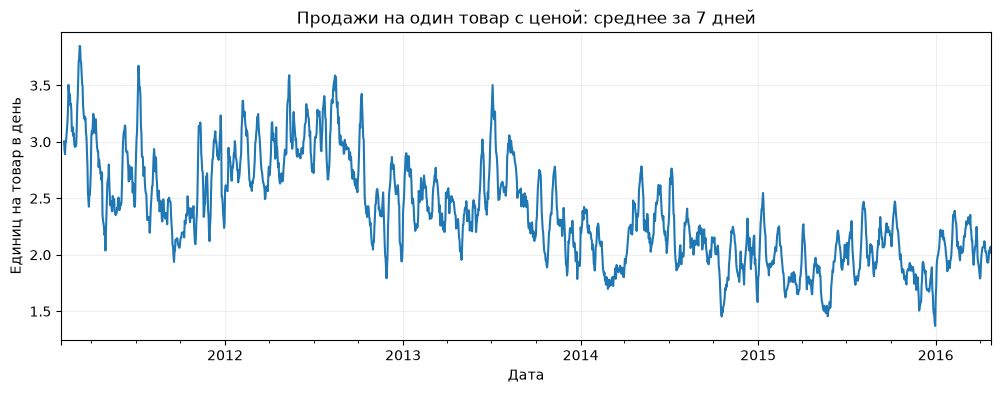

In [11]:
daily["sales_per_item"] = (
    daily["total_sales"] / daily["products_with_price"]
)

daily["sales_per_item"].rolling(7).mean().plot(figsize=(12, 4))

plt.title("Продажи на один товар с ценой: среднее за 7 дней")
plt.ylabel("Единиц на товар в день")
plt.xlabel("Дата")
plt.grid(alpha=0.2)
plt.show()

Чтобы разобраться с изменением состава, берём 49 товаров, у которых цена была уже в первый день. Сравниваем их средние продажи с меняющимся набором; обе линии сглажены за 28 дней.

У фиксированной группы продажи тоже снижаются. Значит, расширение набора объясняет не всю динамику. Эти 49 товаров нужны только для двух графиков: модели дальше обучаются на всех выбранных 100.

В фиксированном наборе: 49 товаров


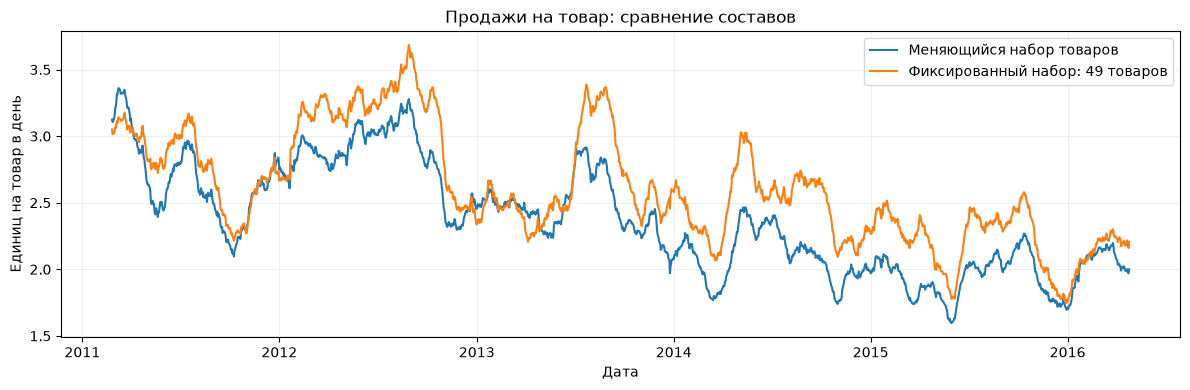

In [12]:
first_date = panel["date"].min()

initial_items = panel.loc[
    panel["date"].eq(first_date) & panel["price_available"],
    "item_id",
].unique()

fixed_panel = panel.loc[panel["item_id"].isin(initial_items)]
fixed_daily = fixed_panel.groupby("date")["sales"].mean()

print(f"В фиксированном наборе: {len(initial_items)} товаров")

fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(
    daily.index,
    daily["sales_per_item"].rolling(28).mean(),
    label="Меняющийся набор товаров",
)
ax.plot(
    fixed_daily.index,
    fixed_daily.rolling(28).mean(),
    label=f"Фиксированный набор: {len(initial_items)} товаров",
)

ax.set_title("Продажи на товар: сравнение составов")
ax.set_ylabel("Единиц на товар в день")
ax.set_xlabel("Дата")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

Считаем средние продажи фиксированной группы для каждого дня недели. `dayofweek` нумерует дни от понедельника (0) до воскресенья (6).

В этой группе заметно больше продаж в субботу и воскресенье.

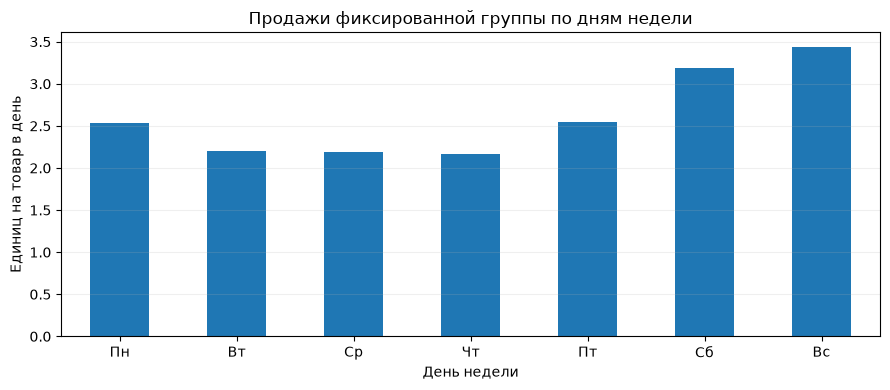

In [13]:
weekday_names = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]

weekday_sales = (
    fixed_daily
    .groupby(fixed_daily.index.dayofweek)
    .mean()
    .reindex(range(7))
)

fig, ax = plt.subplots(figsize=(9, 4))

weekday_sales.plot.bar(ax=ax)
ax.set_xticklabels(weekday_names, rotation=0)
ax.set_title("Продажи фиксированной группы по дням недели")
ax.set_ylabel("Единиц на товар в день")
ax.set_xlabel("День недели")
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

## 4. Простой недельный прогноз

После завершения воскресенья прогнозируем продажи каждого товара за следующий понедельник–воскресенье.

Сначала попробуем три простых метода: повторить прошлую неделю, взять среднее или медиану четырёх прошлых недель. Это baselines, с которыми будем сравнивать CatBoost.

Суммируем продажи по полным календарным неделям отдельно для каждого товара и магазина. `W-SUN` означает, что неделя заканчивается в воскресенье. Первые два дня истории, 29–30 января 2011 года, составляют неполную неделю и исключаются.

После сортировки `shift(1)` переносит продажи прошлой недели в прогноз текущей. Например, для 1–7 февраля 2016 года прогнозом будут продажи 25–31 января.

In [14]:
weekly = (
    panel.groupby([
        pd.Grouper(key="date", freq="W-SUN"),
        "store_id",
        "item_id",
    ])
    .agg(
        weekly_sales=("sales", "sum"),
        days_in_week=("date", "nunique"),
    )
    .reset_index()
    .rename(columns={"date": "week_end"})
)

weekly = weekly.loc[weekly["days_in_week"].eq(7)].copy()

weekly = weekly.sort_values(
    ["store_id", "item_id", "week_end"]
).reset_index(drop=True)

weekly["prediction"] = (
    weekly.groupby(["store_id", "item_id"])["weekly_sales"]
    .shift(1)
)

Внутри каждого ряда считаем среднее и медиану четырёх предыдущих недель.

Порядок важен: сначала `shift(1)`, затем `rolling(4)`. Так продажи прогнозируемой недели не попадут в расчёт её же прогноза. В начале истории, пока четырёх прошлых недель ещё нет, получаются пропуски.

In [15]:
weekly["prediction_mean_4w"] = (
    weekly.groupby(["store_id", "item_id"])["weekly_sales"]
    .transform(lambda s: s.shift(1).rolling(4).mean())
)

weekly["prediction_median_4w"] = (
    weekly.groupby(["store_id", "item_id"])["weekly_sales"]
    .transform(lambda s: s.shift(1).rolling(4).median())
)

## 5. Проверка по времени

Модель учится на прошлом и проверяется на более поздних датах. Делим историю подряд: обучение, валидация для выбора модели, затем тест.

Проверяем недельные прогнозы по очереди. Когда наступает вторая проверочная неделя, продажи первой уже известны и могут входить в признаки. Для прогноза сразу всех восьми недель понадобился бы другой расчёт.

Разбиваем полные недели на три части:

- обучение: 31 января 2011 года — 31 января 2016 года, 261 неделя;
- валидация: 1 февраля — 27 марта 2016 года, 8 недель и 800 строк;
- тест: 28 марта — 24 апреля 2016 года, 4 недели и 400 строк.

На этапе 6 из обучения ещё уберём строки без нужной истории. Тестовые метрики посчитаем в разделе 7, после выбора модели по валидации.

In [16]:
week_dates = (
    weekly["week_end"]
    .drop_duplicates()
    .sort_values()
    .tolist()
)

validation_dates = week_dates[-12:-4]

TRAIN_END = week_dates[-13]
VALIDATION_END = week_dates[-5]

weekly["split"] = np.select(
    [
        weekly["week_end"].le(TRAIN_END),
        weekly["week_end"].le(VALIDATION_END),
    ],
    ["train", "validation"],
    default="test",
)

split_summary = (
    weekly.groupby("split")
    .agg(
        weeks=("week_end", "nunique"),
        observations=("weekly_sales", "size"),
    )
    .reindex(["train", "validation", "test"])
)

display(split_summary)

,weeks,observations
split,,
train,261,26100
validation,8,800
test,4,400


Проверяем прогноз «как на прошлой неделе» на восьми неделях валидации. Для каждой строки считаем модуль ошибки: `abs(прогноз − факт)`.

MAE — средняя абсолютная ошибка, в единицах товара за неделю. WAPE — сумма абсолютных ошибок, делённая на суммарные фактические продажи. Здесь получаем MAE 5,23 и WAPE 34,84%.

Ниже — первые примеры прогнозов и ошибок.

In [17]:
validation = weekly.loc[
    weekly["week_end"].isin(validation_dates)
    & weekly["prediction"].notna()
].copy()

validation["absolute_error"] = (
    validation["prediction"] - validation["weekly_sales"]
).abs()

mae = validation["absolute_error"].mean()
wape = (
    validation["absolute_error"].sum()
    / validation["weekly_sales"].sum()
)

print(f"Проверочных недель: {len(validation_dates)}")
print(f"Прогнозов товар-неделя: {len(validation)}")
print(f"MAE: {mae:.2f} единиц на товар за неделю")
print(f"WAPE: {wape:.2%}")

example = validation.loc[
    validation["week_end"].eq(validation_dates[0])
]

display(
    example[
        ["week_end", "item_id", "weekly_sales",
         "prediction", "absolute_error"]
    ].head(10)
)

Проверочных недель: 8
Прогнозов товар-неделя: 800
MAE: 5.23 единиц на товар за неделю
WAPE: 34.84%


,week_end,item_id,weekly_sales,prediction,absolute_error
261,2016-02-07,FOODS_1_063,0,0.0,0.0
534,2016-02-07,FOODS_1_089,2,0.0,2.0
807,2016-02-07,FOODS_1_095,0,0.0,0.0
1080,2016-02-07,FOODS_1_110,17,31.0,14.0
1353,2016-02-07,FOODS_1_118,10,28.0,18.0
1626,2016-02-07,FOODS_1_122,8,7.0,1.0
1899,2016-02-07,FOODS_1_129,3,6.0,3.0
2172,2016-02-07,FOODS_1_141,7,4.0,3.0
2445,2016-02-07,FOODS_1_177,8,5.0,3.0
2718,2016-02-07,FOODS_1_187,9,6.0,3.0


Сравниваем прошлую неделю со средним четырёх недель на одинаковых 800 строках. `assert` проверяет, что все прогнозы заполнены.

Среднее оказалось лучше: MAE 4,84 и WAPE 32,28%. На одной и той же выборке MAE и WAPE ранжируют методы одинаково: сумма абсолютных ошибок у них общая, а знаменатели постоянны.

In [18]:
comparison = weekly.loc[
    weekly["week_end"].isin(validation_dates)
].copy()

prediction_columns = ["prediction", "prediction_mean_4w"]
assert comparison[prediction_columns].notna().all().all()

results = []

for name, column in [
    ("Предыдущая неделя", "prediction"),
    ("Среднее за 4 недели", "prediction_mean_4w"),
]:
    absolute_error = (
        comparison[column] - comparison["weekly_sales"]
    ).abs()

    results.append({
        "Метод": name,
        "MAE": absolute_error.mean(),
        "WAPE": absolute_error.sum() / comparison["weekly_sales"].sum(),
    })

baseline_results = pd.DataFrame(results).set_index("Метод")

display(
    baseline_results.style.format({
        "MAE": "{:.2f}",
        "WAPE": "{:.2%}",
    })
)

,MAE,WAPE
Метод,,
Предыдущая неделя,5.23,34.84%
Среднее за 4 недели,4.84,32.28%


Разбиваем ошибку по неделям. `gain` — разница MAE прошлого недельного значения и среднего четырёх недель. Если он положительный, среднее лучше.

Среднее выигрывает в семи из восьми недель. Самый большой выигрыш — на неделе до 20 марта.

In [19]:
weekly_comparison = comparison.copy()

weekly_comparison["error_last_week"] = (
    weekly_comparison["prediction"]
    - weekly_comparison["weekly_sales"]
).abs()

weekly_comparison["error_mean_4w"] = (
    weekly_comparison["prediction_mean_4w"]
    - weekly_comparison["weekly_sales"]
).abs()

mae_by_week = weekly_comparison.groupby("week_end").agg(
    mae_last_week=("error_last_week", "mean"),
    mae_mean_4w=("error_mean_4w", "mean"),
)

mae_by_week["gain"] = (
    mae_by_week["mae_last_week"] - mae_by_week["mae_mean_4w"]
)

display(mae_by_week.round(2))

,mae_last_week,mae_mean_4w,gain
week_end,,,
2016-02-07,5.51,4.96,0.55
2016-02-14,5.90,5.46,0.44
2016-02-21,4.62,4.38,0.24
2016-02-28,5.31,4.57,0.74
2016-03-06,4.22,4.16,0.06
2016-03-13,5.35,5.12,0.23
2016-03-20,5.50,4.46,1.04
2016-03-27,5.42,5.64,-0.22


## 6. CatBoost и анализ ошибок

Обучим общую модель для 100 товаров. Для каждой недели дадим ей прошлые продажи, несколько статистик и календарные признаки. Предсказать нужно `weekly_sales` — сумму продаж за эту неделю.

Все варианты в этом разделе сравниваем на восьми неделях валидации.

Собираем признаки отдельно для каждого ряда:

- `lag_1w`–`lag_4w` — продажи одной, двух, трёх и четырёх недель назад;
- `mean_4w`, `mean_8w` — средние за четыре и восемь прошлых недель;
- `std_4w` — стандартное отклонение продаж за четыре прошлые недели;
- `month`, `week_of_year` — месяц и номер прогнозируемой недели.

Добавляем `store_id` и `item_id` как категории. Всего 11 признаков. `weekly_sales` оставляем отдельно как ответ.

Перед скользящими расчётами снова стоит `shift(1)`. Для недели 1–7 февраля признаки используют продажи только до 31 января. Первые восемь недель без полного окна `mean_8w` дадут пропуски.

In [20]:
model_data = (
    weekly.sort_values(["store_id", "item_id", "week_end"])
    .reset_index(drop=True)
    .copy()
)

grouped_sales = model_data.groupby(
    ["store_id", "item_id"]
)["weekly_sales"]

for lag in [1, 2, 3, 4]:
    model_data[f"lag_{lag}w"] = grouped_sales.shift(lag)

model_data["mean_4w"] = grouped_sales.transform(
    lambda s: s.shift(1).rolling(4).mean()
)

model_data["mean_8w"] = grouped_sales.transform(
    lambda s: s.shift(1).rolling(8).mean()
)

model_data["std_4w"] = grouped_sales.transform(
    lambda s: s.shift(1).rolling(4).std()
)

model_data["month"] = model_data["week_end"].dt.month

model_data["week_of_year"] = (
    model_data["week_end"].dt.isocalendar().week.astype(int)
)

categorical_features = ["store_id", "item_id"]

numeric_features = [
    "lag_1w", "lag_2w", "lag_3w", "lag_4w",
    "mean_4w", "mean_8w", "std_4w",
    "month", "week_of_year",
]

feature_columns = categorical_features + numeric_features

view_columns = [
    "week_end", "item_id",
    "lag_1w", "mean_4w", "mean_8w", "std_4w",
    "weekly_sales",
]

display(
    model_data.loc[
        model_data["week_end"].eq(validation_dates[0]),
        view_columns,
    ].head(10).round(2)
)

/var/folders/_5/xfqsygpn717bwxf2_1nbmcvh0000gn/T/ipykernel_29227/2842581334.py:52: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(10).round(2)


,week_end,item_id,lag_1w,mean_4w,mean_8w,std_4w,weekly_sales
261,2016-02-07,FOODS_1_063,0.0,0.00,0.00,0.00,0
534,2016-02-07,FOODS_1_089,0.0,0.25,0.12,0.50,2
807,2016-02-07,FOODS_1_095,0.0,0.25,0.75,0.50,0
1080,2016-02-07,FOODS_1_110,31.0,29.25,29.12,8.26,17
1353,2016-02-07,FOODS_1_118,28.0,14.75,17.38,8.85,10
1626,2016-02-07,FOODS_1_122,7.0,9.50,12.38,1.73,8
1899,2016-02-07,FOODS_1_129,6.0,5.75,5.62,2.50,3
2172,2016-02-07,FOODS_1_141,4.0,5.00,5.88,3.46,7
2445,2016-02-07,FOODS_1_177,5.0,5.75,6.38,0.96,8
2718,2016-02-07,FOODS_1_187,6.0,5.50,4.88,1.29,9


Оставляем в обучении строки с достаточной историей. К моменту прогноза у товара уже должна быть хотя бы одна запись о цене. Нули продаж после её появления сохраняем. Окна считаются по календарным неделям.

В `X_train` и `X_valid` попадают признаки, в `y_train` и `y_valid` — фактические продажи. Идентификаторы приводим к строковому типу для CatBoost. Проверки требуют сохранить все строки валидации.

Получилось 21 010 строк обучения и 800 строк валидации.

In [21]:
first_price_dates = (
    panel.loc[panel["price_available"]]
    .groupby(["store_id", "item_id"])["date"]
    .min()
    .rename("first_price_date")
)

prepared = model_data.join(
    first_price_dates,
    on=["store_id", "item_id"],
)

forecast_origin = prepared["week_end"] - pd.Timedelta(days=7)

known_at_origin = prepared["first_price_date"].le(forecast_origin)

for column in categorical_features:
    prepared[column] = prepared[column].astype(str).astype(object)

train_data = prepared.loc[
    prepared["split"].eq("train") & known_at_origin
].dropna(subset=numeric_features).copy()

valid_data = prepared.loc[
    prepared["split"].eq("validation")
].copy()

assert len(valid_data) == len(comparison) == N_ITEMS * len(validation_dates)
assert known_at_origin.loc[valid_data.index].all()
assert valid_data[numeric_features].notna().all().all()

X_train = train_data[feature_columns]
y_train = train_data["weekly_sales"]

X_valid = valid_data[feature_columns]
y_valid = valid_data["weekly_sales"]

print(f"Строк для обучения: {len(train_data):,}")
print(f"Строк для проверки: {len(valid_data):,}")
print(f"Признаков: {len(feature_columns)}")

Строк для обучения: 21,010
Строк для проверки: 800
Признаков: 11


Начинаем с 1 000 деревьев глубиной 6 и шагом обучения 0,05. Обучаем с MAE и по MAE же выбираем лучшую итерацию на валидации.

Если улучшения нет 100 итераций подряд, обучение останавливается. `use_best_model=True` оставляет деревья до лучшей итерации — здесь их 164.

В журнале CatBoost слово `test` обозначает переданный `eval_set`. Здесь это наша валидация; четыре последние тестовые недели в обучение не передаются.

In [22]:
model = CatBoostRegressor(
    iterations=1000,
    depth=6,
    learning_rate=0.05,
    loss_function="MAE",
    eval_metric="MAE",
    random_seed=RANDOM_STATE,
    thread_count=4,
    allow_writing_files=False,
)

model.fit(
    X_train,
    y_train,
    cat_features=categorical_features,
    eval_set=(X_valid, y_valid),
    early_stopping_rounds=100,
    use_best_model=True,
    verbose=100,
)

print(f"Деревьев в итоговой модели: {model.tree_count_}")

0:	learn: 13.1864745	test: 11.7336240	best: 11.7336240 (0)	total: 68.6ms	remaining: 1m 8s


100:	learn: 5.4521543	test: 4.6713641	best: 4.6713641 (100)	total: 355ms	remaining: 3.16s


200:	learn: 5.3396975	test: 4.6287124	best: 4.6240121 (163)	total: 620ms	remaining: 2.46s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 4.624012127
bestIteration = 163

Shrink model to first 164 iterations.
Деревьев в итоговой модели: 164


Предсказываем продажи 800 проверочных строк. Отрицательные прогнозы заменяем нулём, дробные значения оставляем.

CatBoost получил MAE 4,62 и WAPE 30,81%. Это немного лучше среднего четырёх недель с его MAE 4,84. Модель обучена один раз на `train`; признаки каждой следующей недели учитывают уже завершившиеся недели.

In [23]:
evaluation = valid_data[
    [
        "week_end",
        "store_id",
        "item_id",
        "weekly_sales",
        "prediction",
        "prediction_mean_4w",
        "prediction_median_4w",
    ]
].copy()

evaluation["prediction_catboost"] = np.maximum(
    0,
    model.predict(X_valid),
)

methods = {
    "Предыдущая неделя": "prediction",
    "Среднее за 4 недели": "prediction_mean_4w",
    "CatBoost": "prediction_catboost",
}

results = []

for method, column in methods.items():
    absolute_error = (
        evaluation["weekly_sales"] - evaluation[column]
    ).abs()

    results.append({
        "Метод": method,
        "MAE": absolute_error.mean(),
        "WAPE": absolute_error.sum() / evaluation["weekly_sales"].sum(),
    })

model_results = pd.DataFrame(results).set_index("Метод")

display(
    model_results.style.format({
        "MAE": "{:.2f}",
        "WAPE": "{:.2%}",
    })
)

,MAE,WAPE
Метод,,
Предыдущая неделя,5.23,34.84%
Среднее за 4 недели,4.84,32.28%
CatBoost,4.62,30.81%


Смотрим MAE CatBoost и среднего четырёх недель по отдельным неделям. Положительный `gain` означает выигрыш модели.

CatBoost лучше в шести из восьми недель. Самая большая разница — на неделе до 27 марта.

In [24]:
weekly_model_comparison = (
    evaluation.assign(
        error_mean_4w=lambda df: (
            df["weekly_sales"] - df["prediction_mean_4w"]
        ).abs(),
        error_catboost=lambda df: (
            df["weekly_sales"] - df["prediction_catboost"]
        ).abs(),
    )
    .groupby("week_end")
    .agg(
        mae_mean_4w=("error_mean_4w", "mean"),
        mae_catboost=("error_catboost", "mean"),
    )
)

weekly_model_comparison["gain"] = (
    weekly_model_comparison["mae_mean_4w"]
    - weekly_model_comparison["mae_catboost"]
)

display(weekly_model_comparison.round(2))

wins = weekly_model_comparison["gain"].gt(0).sum()
print(f"CatBoost лучше в {wins} из {len(weekly_model_comparison)} недель")

,mae_mean_4w,mae_catboost,gain
week_end,,,
2016-02-07,4.96,5.07,-0.11
2016-02-14,5.46,5.06,0.39
2016-02-21,4.38,4.01,0.37
2016-02-28,4.57,4.22,0.35
2016-03-06,4.16,4.07,0.09
2016-03-13,5.12,5.07,0.04
2016-03-20,4.46,4.55,-0.09
2016-03-27,5.64,4.92,0.73


CatBoost лучше в 6 из 8 недель


Теперь сравниваем ошибки по товарам. В таблице — десять товаров с самым большим MAE CatBoost. `actual_total` показывает продажи за весь проверочный период, `mean_signed_error` — среднюю разность «прогноз − факт». Минус означает занижение, плюс — завышение.

Для 50 из 100 товаров MAE уменьшился. Суммарный прогноз — 11 263,7 единицы при факте 12 006: занижение на 6,18%. При этом ошибки разных товаров могут компенсировать друг друга.

In [25]:
error_analysis = evaluation.copy()

error_analysis["error_mean_4w"] = (
    error_analysis["prediction_mean_4w"]
    - error_analysis["weekly_sales"]
).abs()

error_analysis["error_catboost"] = (
    error_analysis["prediction_catboost"]
    - error_analysis["weekly_sales"]
).abs()

error_analysis["signed_error"] = (
    error_analysis["prediction_catboost"]
    - error_analysis["weekly_sales"]
)

item_errors = (
    error_analysis.groupby("item_id")
    .agg(
        actual_total=("weekly_sales", "sum"),
        mae_mean_4w=("error_mean_4w", "mean"),
        mae_catboost=("error_catboost", "mean"),
        mean_signed_error=("signed_error", "mean"),
    )
)

item_errors["gain"] = (
    item_errors["mae_mean_4w"] - item_errors["mae_catboost"]
)

wins = item_errors["gain"].gt(0).sum()
print(f"CatBoost лучше для {wins} из {len(item_errors)} товаров")

actual_total = error_analysis["weekly_sales"].sum()
predicted_total = error_analysis["prediction_catboost"].sum()
volume_bias = (predicted_total - actual_total) / actual_total

print(f"Продано за проверочный период: {actual_total:,.0f}")
print(f"Суммарный прогноз CatBoost: {predicted_total:,.1f}")
print(f"Отклонение суммарного прогноза: {volume_bias:+.2%}")

display(
    item_errors.sort_values("mae_catboost", ascending=False)
    .head(10)
    .round(2)
)

CatBoost лучше для 50 из 100 товаров
Продано за проверочный период: 12,006
Суммарный прогноз CatBoost: 11,263.7
Отклонение суммарного прогноза: -6.18%


,actual_total,mae_mean_4w,mae_catboost,mean_signed_error,gain
item_id,,,,,
FOODS_3_760,874,33.28,34.86,11.28,-1.58
FOODS_3_080,1069,17.41,15.94,-9.35,1.47
FOODS_3_526,305,17.34,15.70,4.98,1.64
FOODS_3_302,350,15.03,15.45,-6.88,-0.42
FOODS_3_007,239,17.31,14.97,-3.39,2.34
FOODS_3_097,460,14.41,14.67,-9.77,-0.26
FOODS_3_039,347,18.31,14.64,-10.42,3.67
FOODS_3_511,1351,12.31,12.63,-11.37,-0.32
FOODS_3_133,401,9.50,10.10,-5.43,-0.60


Проверим, как на результат влияет функция обучения. Данные и основные настройки оставляем теми же, MAE меняем на RMSE. Лучшую итерацию всё ещё выбираем по MAE валидации. Новая модель — `model_rmse`, первая остаётся в `model`.

RMSE сильнее штрафует большие промахи. Ещё одно различие: для значений `0, 0, 0, 0, 10` лучший постоянный прогноз по MAE — 0, по квадратичной ошибке — 2. Поэтому MAE может давать хороший результат по отдельным строкам и одновременно занижать общий объём.

In [26]:
rmse_params = model.get_params().copy()
rmse_params["loss_function"] = "RMSE"
rmse_params["eval_metric"] = "MAE"

model_rmse = CatBoostRegressor(**rmse_params)

model_rmse.fit(
    X_train,
    y_train,
    cat_features=categorical_features,
    eval_set=(X_valid, y_valid),
    early_stopping_rounds=100,
    use_best_model=True,
    verbose=100,
)

evaluation["prediction_catboost_rmse"] = np.maximum(
    0,
    model_rmse.predict(X_valid),
)

0:	learn: 15.1348158	test: 14.1816157	best: 14.1816157 (0)	total: 3.15ms	remaining: 3.15s


100:	learn: 5.5914300	test: 4.9269448	best: 4.9269448 (100)	total: 188ms	remaining: 1.68s


200:	learn: 5.3769104	test: 4.9273804	best: 4.8980036 (127)	total: 373ms	remaining: 1.48s


Stopped by overfitting detector  (100 iterations wait)

bestTest = 4.898003589
bestIteration = 127

Shrink model to first 128 iterations.


Добавляем Bias: `(сумма прогнозов − сумма фактов) / сумма фактов`. Плюс означает завышение общего объёма, минус — занижение. Ошибки отдельных товаров при этом могут компенсироваться.

У CatBoost с RMSE Bias стал −0,30%, а MAE вырос до 4,90. По суммарному объёму он ближе к факту, по MAE хуже первой модели. Пока выбираем CatBoost с MAE.

In [27]:
methods = {
    "Предыдущая неделя": "prediction",
    "Среднее за 4 недели": "prediction_mean_4w",
    "CatBoost — обучение MAE": "prediction_catboost",
    "CatBoost — обучение RMSE": "prediction_catboost_rmse",
}

actual_total = evaluation["weekly_sales"].sum()
results = []

for method, column in methods.items():
    absolute_error = (
        evaluation[column] - evaluation["weekly_sales"]
    ).abs()

    results.append({
        "Метод": method,
        "MAE": absolute_error.mean(),
        "WAPE": absolute_error.sum() / actual_total,
        "Bias": (
            evaluation[column].sum() - actual_total
        ) / actual_total,
    })

loss_comparison = pd.DataFrame(results).set_index("Метод")

display(
    loss_comparison.style.format({
        "MAE": "{:.2f}",
        "WAPE": "{:.2%}",
        "Bias": "{:+.2%}",
    })
)

,MAE,WAPE,Bias
Метод,,,
Предыдущая неделя,5.23,34.84%,-0.19%
Среднее за 4 недели,4.84,32.28%,-0.94%
CatBoost — обучение MAE,4.62,30.81%,-6.18%
CatBoost — обучение RMSE,4.90,32.64%,-0.30%


Добавляем медиану четырёх недель в общую таблицу. У неё MAE 5,01, WAPE 33,36% и Bias −2,29%.

Лучший простой метод на валидации — среднее четырёх недель. Связь MAE с медианой не означает, что медиана всего четырёх прошлых значений обязательно даст лучший прогноз.

In [28]:
assert evaluation["prediction_median_4w"].notna().all()

prediction = evaluation["prediction_median_4w"]
actual = evaluation["weekly_sales"]
absolute_error = (prediction - actual).abs()

median_result = pd.DataFrame(
    {
        "MAE": [absolute_error.mean()],
        "WAPE": [absolute_error.sum() / actual.sum()],
        "Bias": [(prediction.sum() - actual.sum()) / actual.sum()],
    },
    index=["Медиана за 4 недели"],
)

extended_comparison = pd.concat([
    loss_comparison,
    median_result,
])

display(
    extended_comparison.style.format({
        "MAE": "{:.2f}",
        "WAPE": "{:.2%}",
        "Bias": "{:+.2%}",
    })
)

,MAE,WAPE,Bias
Предыдущая неделя,5.23,34.84%,-0.19%
Среднее за 4 недели,4.84,32.28%,-0.94%
CatBoost — обучение MAE,4.62,30.81%,-6.18%
CatBoost — обучение RMSE,4.90,32.64%,-0.30%
Медиана за 4 недели,5.01,33.36%,-2.29%


Смотрим важность признаков первой модели. CatBoost оценивает их вклад в изменение прогнозов; сумма оценок равна 100. Это не проценты улучшения точности.

Модель в основном использует лаги продаж. У `store_id` и `item_id` важность нулевая. Магазин в нашей выборке один, а идентификатор товара здесь не получил важности. На другой выборке результат может быть другим.

[Описание расчёта в CatBoost](https://catboost.ai/docs/en/concepts/fstr#predictionvalueschange).

In [29]:
feature_importance = (
    pd.DataFrame({
        "feature": model.feature_names_,
        "importance": model.get_feature_importance(),
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

display(feature_importance.round(2))

,feature,importance
0,lag_1w,33.46
1,lag_4w,24.60
2,lag_3w,19.37
3,lag_2w,10.25
4,mean_4w,5.31
5,mean_8w,4.43
6,std_4w,1.58
7,week_of_year,0.55
8,month,0.45
9,store_id,0.00


## 7. Результаты и следующие шаги

На валидации выбрали CatBoost с MAE и 164 деревьями. Теперь переобучаем его на `train + validation` и проверяем последние четыре недели: 28 марта — 24 апреля 2016 года.

Число деревьев и остальные настройки выбраны до расчёта тестовых метрик. Прогнозируем по одной неделе вперёд, как и раньше: факты уже завершившихся недель доступны для следующего прогноза.

Проверяем выбор по валидации и собираем финальное обучение. Условия те же: достаточно прошлых недель и есть запись о цене к моменту прогноза.

Получается 21 810 обучающих строк и 400 тестовых. `assert` проверяет даты, число строк и наличие признаков. Все обучающие недели должны закончиться раньше первой тестовой.

In [30]:
selected_model_name = "CatBoost — обучение MAE"
selected_baseline_name = "Среднее за 4 недели"
selected_iterations = int(model.tree_count_)

assert extended_comparison["MAE"].idxmin() == selected_model_name

final_train_data = prepared.loc[
    prepared["split"].isin(["train", "validation"]) & known_at_origin
].dropna(subset=numeric_features).copy()

test_data = prepared.loc[prepared["split"].eq("test")].copy()
test_dates = sorted(test_data["week_end"].unique())

assert len(test_dates) == 4
assert len(test_data) == N_ITEMS * len(test_dates)
assert final_train_data["week_end"].max() == VALIDATION_END
assert test_data["week_end"].min() > final_train_data["week_end"].max()
assert known_at_origin.loc[test_data.index].all()
assert test_data[feature_columns].notna().all().all()

X_final_train = final_train_data[feature_columns]
y_final_train = final_train_data["weekly_sales"]
X_test = test_data[feature_columns]

print(f"Выбранная модель: {selected_model_name}")
print(f"Зафиксировано деревьев: {selected_iterations}")
print(f"Строк финального обучения: {len(final_train_data):,}")
print(f"Тестовых прогнозов: {len(test_data):,}")
print(
    f"Тестовый период: "
    f"{test_data['week_end'].min() - pd.Timedelta(days=6):%Y-%m-%d} — "
    f"{test_data['week_end'].max():%Y-%m-%d}"
)

Выбранная модель: CatBoost — обучение MAE
Зафиксировано деревьев: 164
Строк финального обучения: 21,810
Тестовых прогнозов: 400
Тестовый период: 2016-03-28 — 2016-04-24


Обучаем новую модель с выбранными 164 деревьями на `train + validation`. Здесь нет `eval_set` и ранней остановки: число деревьев уже известно.

Результат сохраняем в `final_model`. Первая модель `model` остаётся для сравнения результатов на валидации.

In [31]:
final_params = model.get_params().copy()
final_params.update(
    iterations=selected_iterations,
    use_best_model=False,
)

final_model = CatBoostRegressor(**final_params)
final_model.fit(
    X_final_train,
    y_final_train,
    cat_features=categorical_features,
    verbose=False,
)

assert final_model.tree_count_ == selected_iterations
print(f"Финальная модель обучена: {final_model.tree_count_} деревьев")

Финальная модель обучена: 164 деревьев


Получаем 400 прогнозов финальной модели и сравниваем с тремя простыми методами. `forecast_origin` — конец предыдущей недели, то есть дата доступной истории для прогноза.

В таблице рядом стоят метрики валидации и теста. У CatBoost они получены на разных версиях модели: первая обучена на `train`, финальная — на `train + validation`.

In [32]:
test_evaluation = test_data[
    [
        "week_end", "store_id", "item_id", "weekly_sales",
        "prediction", "prediction_mean_4w", "prediction_median_4w",
    ]
].copy()

test_evaluation["forecast_origin"] = (
    test_evaluation["week_end"] - pd.Timedelta(days=FORECAST_HORIZON)
)
test_evaluation["prediction_catboost"] = np.maximum(
    0, final_model.predict(X_test)
)

test_methods = {
    "Предыдущая неделя": "prediction",
    "Среднее за 4 недели": "prediction_mean_4w",
    "Медиана за 4 недели": "prediction_median_4w",
    selected_model_name: "prediction_catboost",
}

test_actual_total = test_evaluation["weekly_sales"].sum()
assert test_actual_total > 0
assert test_evaluation[list(test_methods.values())].notna().all().all()

test_scores = []
for method, column in test_methods.items():
    error = test_evaluation[column] - test_evaluation["weekly_sales"]
    test_scores.append({
        "Метод": method,
        "MAE": error.abs().mean(),
        "WAPE": error.abs().sum() / test_actual_total,
        "Bias": error.sum() / test_actual_total,
    })

test_results = pd.DataFrame(test_scores).set_index("Метод")
final_comparison = (
    extended_comparison.loc[test_results.index, ["MAE", "WAPE"]]
    .add_prefix("validation_")
    .join(test_results.add_prefix("test_"))
)

display(
    final_comparison.style.format({
        "validation_MAE": "{:.2f}",
        "validation_WAPE": "{:.2%}",
        "test_MAE": "{:.2f}",
        "test_WAPE": "{:.2%}",
        "test_Bias": "{:+.2%}",
    })
)

,validation_MAE,validation_WAPE,test_MAE,test_WAPE,test_Bias
Метод,,,,,
Предыдущая неделя,5.23,34.84%,4.94,35.27%,-0.52%
Среднее за 4 недели,4.84,32.28%,4.28,30.58%,+1.97%
Медиана за 4 недели,5.01,33.36%,4.29,30.68%,-0.03%
CatBoost — обучение MAE,4.62,30.81%,4.21,30.05%,-2.61%


Сравниваем CatBoost со средним четырёх недель на каждой тестовой неделе. Положительный `gain` — выигрыш CatBoost.

Общий MAE ниже на 1,75%, модель лучше в двух из четырёх недель. Основной выигрыш пришёлся на первую неделю; в двух последних среднее оказалось лучше.

In [33]:
test_weekly_comparison = (
    test_evaluation.assign(
        error_mean_4w=lambda df: (
            df["prediction_mean_4w"] - df["weekly_sales"]
        ).abs(),
        error_catboost=lambda df: (
            df["prediction_catboost"] - df["weekly_sales"]
        ).abs(),
    )
    .groupby("week_end")
    .agg(
        mae_mean_4w=("error_mean_4w", "mean"),
        mae_catboost=("error_catboost", "mean"),
    )
)

test_weekly_comparison["gain"] = (
    test_weekly_comparison["mae_mean_4w"]
    - test_weekly_comparison["mae_catboost"]
)

test_mae_gain = (
    test_results.loc[selected_baseline_name, "MAE"]
    - test_results.loc[selected_model_name, "MAE"]
)
test_relative_gain = (
    test_mae_gain / test_results.loc[selected_baseline_name, "MAE"]
)
test_weekly_wins = int(test_weekly_comparison["gain"].gt(0).sum())

display(test_weekly_comparison.round(2))
print(f"Изменение MAE относительно среднего 4 недель: {test_relative_gain:+.2%}")
print(f"CatBoost лучше в {test_weekly_wins} из {len(test_dates)} тестовых недель")
print(f"Фактический тестовый объём: {test_actual_total:,.0f}")
print(f"Суммарный прогноз CatBoost: {test_evaluation['prediction_catboost'].sum():,.1f}")

,mae_mean_4w,mae_catboost,gain
week_end,,,
2016-04-03,4.76,4.16,0.61
2016-04-10,3.96,3.92,0.04
2016-04-17,4.36,4.46,-0.10
2016-04-24,4.04,4.29,-0.25


Изменение MAE относительно среднего 4 недель: +1.75%
CatBoost лучше в 2 из 4 тестовых недель
Фактический тестовый объём: 5,599
Суммарный прогноз CatBoost: 5,452.9


В `results/weekly_pilot` сохраняем метрики, все 400 прогнозов, сравнение по неделям и описание запуска. Финальная модель записывается в `models/catboost_weekly_pilot.cbm`.

Таблицы результатов можно сохранить в Git. Файл модели исключён из Git и создаётся при запуске этого раздела.

In [34]:
import json

pilot_results_dir = RESULTS / "weekly_pilot"
pilot_results_dir.mkdir(parents=True, exist_ok=True)
final_model_path = PROJECT_ROOT / "models" / "catboost_weekly_pilot.cbm"
final_model_path.parent.mkdir(parents=True, exist_ok=True)

test_results.to_csv(pilot_results_dir / "test_metrics.csv", index_label="Метод")
final_comparison.to_csv(
    pilot_results_dir / "validation_test_comparison.csv", index_label="Метод"
)
test_weekly_comparison.to_csv(pilot_results_dir / "test_metrics_by_week.csv")
test_evaluation.sort_values(["week_end", "store_id", "item_id"]).to_csv(
    pilot_results_dir / "test_predictions.csv",
    index=False,
    date_format="%Y-%m-%d",
)
final_model.save_model(str(final_model_path))

run_summary = {
    "dataset": "M5 sales_train_validation",
    "store_id": STORE_ID,
    "category": CATEGORY,
    "n_items": N_ITEMS,
    "target": "weekly_sales",
    "horizon_days": FORECAST_HORIZON,
    "forecast_protocol": "rolling weekly; previous completed weeks observed",
    "selection_metric": "validation MAE",
    "selected_model": selected_model_name,
    "selected_baseline": selected_baseline_name,
    "selected_iterations": selected_iterations,
    "selection_train_end": TRAIN_END.date().isoformat(),
    "final_train_end": VALIDATION_END.date().isoformat(),
    "final_train_rows": len(final_train_data),
    "test_start": (
        test_evaluation["week_end"].min() - pd.Timedelta(days=6)
    ).date().isoformat(),
    "test_end": test_evaluation["week_end"].max().date().isoformat(),
    "test_rows": len(test_evaluation),
    "feature_columns": feature_columns,
    "model_params": final_model.get_params(),
    "test_metrics": test_results.reset_index().to_dict(orient="records"),
    "relative_test_mae_gain_vs_selected_baseline": float(test_relative_gain),
    "test_weekly_wins": test_weekly_wins,
    "model_file": str(final_model_path.relative_to(PROJECT_ROOT)),
    "limitations": [
        "100 FOODS items in CA_1; not the complete M5 dataset",
        "4 test weeks in one chronological holdout",
        "earlier completed test weeks are observed for later weekly forecasts",
        "EDA includes the full available history",
        "observed sales are not uncensored demand; stock data unavailable",
        "not a Kaggle WRMSSE result or a fixed-origin 28-day forecast",
    ],
}

(pilot_results_dir / "run_summary.json").write_text(
    json.dumps(run_summary, ensure_ascii=False, indent=2) + "\n",
    encoding="utf-8",
)

print(f"Таблицы и описание эксперимента: {pilot_results_dir}")
print(f"Финальная модель: {final_model_path}")

Таблицы и описание эксперимента: /Users/daniilsestov/Desktop/pet_projects/demand-planner/results/weekly_pilot
Финальная модель: /Users/daniilsestov/Desktop/pet_projects/demand-planner/models/catboost_weekly_pilot.cbm


На тесте CatBoost получил MAE 4,21 против 4,28 у среднего четырёх недель. Выигрыш — 1,75%. Общий объём продаж модель занизила на 2,61%.

Пока разница небольшая: модель лучше только в двух из четырёх тестовых недель. Проверены 100 товаров одного магазина. Следующий вопрос — сохранится ли выигрыш на большем наборе и других датах.

Графики исследования строились по всей истории. Тестовые ответы не участвовали в выборе настроек и обучении, но теперь результаты теста уже известны. Для следующих экспериментов нужно заранее выбрать новые периоды проверки.

Остатков, закупочной стоимости и сроков поставки в этих данных нет. Поэтому закупки будем проверять в симуляции с отдельно заданными условиями. Текущие недельные метрики также не являются Kaggle score.

Дальше по проекту:

1. Вынести признаки и обучение из ноутбука в `src`. Прогнать весь ассортимент CA_1, затем остальные магазины, проверяя расход памяти и время обучения.
2. Проверить модель на нескольких временных отрезках. Попробовать календарные события и информацию о цене, доступную на дату прогноза.
3. Для Kaggle сделать отдельный дневной прогноз на 28 дней, сравнить с простым методом по WRMSSE и собрать файл отправки.
4. Добавить оценку разброса будущих продаж и расчёт закупок при ограниченном бюджете. Сравнить дефицит, остатки и затраты разных способов закупки.
5. Собрать демо и оформить GitHub: запуск, описание данных, результаты и ограничения. После этого можно добавить AI-аналитика, который объясняет готовые расчёты.